# Glioblastoma with oxygen

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sisyga/biolgca/blob/glioblastoma-oxygen/docs/source/examples/glioblastoma_oxygen.ipynb)

Glioblastoma cells switch between a migrating ("go") and a proliferating ("grow") phenotype. In the model of
Syga et al. (2024) each cell carries its own switch, inherited with mutations, and the switch responds to the
local cell density; evolution then selects how cells switch. Here the switch responds to **oxygen** instead,
which blood vessels supply and the cells consume (Whiteside et al., in preparation).

This notebook builds the model of `lgca.examples.glioblastoma_oxygen` one mechanism at a time:

1. physical parameters in lattice units;
2. oxygen: diffusion, uptake by cells, and vessels as sources;
3. vessels that tumour cells clog, and stable ones that they do not;
4. the oxygen-dependent go-or-grow switch with evolving κ and θ;
5. division and death in normoxia, hypoxia and anoxia;
6. the whole model in 1D and 2D, and a resection.

In [1]:
# In Google Colab this cell installs BioLGCA (about a minute); elsewhere it does nothing.
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules and importlib.util.find_spec("lgca") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "biolgca @ git+https://github.com/sisyga/biolgca@glioblastoma-oxygen"], check=True)

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from lgca.examples import glioblastoma_oxygen as go
from lgca.fields import PDESpec
from lgca.lattice_state import LatticeState
from lgca.model import ModelSpec, SpaceSpec, StateSpec, TimeSpec, build_model, run_model
from lgca.pipeline import InteractionPipelineSpec
from lgca.plot_data import mean_trait

## 1. Parameters in lattice units

A node is a voxel of tissue 50 µm wide that holds up to $K = 100$ cells, so 1000 nodes span 5 cm. Oxygen is
measured relative to the oxygen of the blood, $O_v$ = 60 mmHg, so it lies between 0 and 1; the switch reads it
directly. `go.Parameters` collects the physical values and their sources; several are marked "to check"
against Whiteside's implementation.

Oxygen obeys (Martínez-González et al. 2012)

$$\partial_t O = D\,\Delta O - \alpha\, n\, \frac{O}{K_m + O},$$

with $n$ the cells at a node, $\alpha$ the maximal uptake of a cell and $K_m$ the Michaelis constant. Oxygen
crosses a node in about a second, cells divide in about a day: at every step the field is at equilibrium with
the cells (the steady solver of the `pde` operator), and only the ratio of diffusion to uptake matters.

In [3]:
parameters = go.Parameters()
lattice = parameters.lattice()
for name, value in lattice.items():
    print(f"{name:18s} {value:.4g}")

# the distance over which a full node uses up the blood's oxygen
penetration = np.sqrt(lattice["diffusion"] / (parameters.capacity * lattice["uptake"]))
print(f"penetration length in full tissue: {penetration:.1f} nodes = {50 * penetration:.0f} µm")
print(f"vessel probability per node: 1D {parameters.vessel_probability(1):.3f}, "
      f"2D {parameters.vessel_probability(2):.4f}")

diffusion          0.8
uptake             0.001013
michaelis_constant 0.04167
penetration length in full tissue: 2.8 nodes = 140 µm
vessel probability per node: 1D 0.250, 2D 0.0625


The penetration length is about three nodes (140 µm), shorter than the 200 µm between vessels: tissue at full
density between vessels runs out of oxygen, and that is what makes the vessels matter.

## 2. Oxygen from vessels

`PDESpec` is the built-in `pde` operator. Uptake by cells is one of its built-in cell terms,
`{"uptake": α, "saturation": K_m}`. The vessels are a field, `vessels`, with 1 where a node holds a vessel;
the reaction `glioblastoma.vessels` relaxes oxygen to 1 there at a very high rate, which holds it at the
blood's value: a Dirichlet point source, written as a reaction so that the solver keeps $O \ge 0$.

We start with the oxygen alone, on a 1D line of 200 nodes with the tumour's first cells at the left.

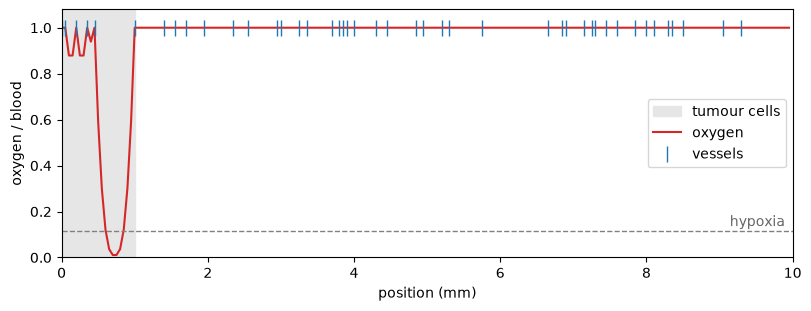

In [4]:
size = 200
vessels = go.build_vessels((size,), parameters, seed=3)
nodes = np.zeros((size, 3), dtype=np.int64)
nodes[:20, 2] = 100  # 1 mm of tissue at full density, resting

oxygen_only = ModelSpec(
    space=SpaceSpec(geometry="lin", dims=size, boundary="reflecting"),
    state=StateSpec(nodes=nodes, restchannels=1, volume_exclusion=False, capacity=100,
                    fields={"oxygen": 1.0, "vessels": vessels}),
    time=TimeSpec(steps=0, seed=1),
    dynamics=InteractionPipelineSpec(operators=[
        PDESpec(field="oxygen", diffusion=lattice["diffusion"], solver="steady",
                reactions=[{"name": "glioblastoma.vessels"}],
                cells=[{"uptake": lattice["uptake"], "saturation": lattice["michaelis_constant"]}]),
    ]),
)
model = build_model(oxygen_only)  # the steady field is solved when the model is built
oxygen = LatticeState(model.lgca).field("oxygen")

x = np.arange(size) * 0.05  # mm
fig, axis = plt.subplots(figsize=(8, 3), constrained_layout=True)
axis.axvspan(0, 1, color="0.9", label="tumour cells")
axis.plot(x, oxygen, color="tab:red", label="oxygen")
axis.plot(x[vessels > 0], np.ones((vessels > 0).sum()), "|", color="tab:blue", markersize=12, label="vessels")
axis.axhline(parameters.hypoxia, ls="--", color="0.5", lw=1)
axis.text(9.9, parameters.hypoxia + 0.02, "hypoxia", ha="right", color="0.4")
axis.set(xlabel="position (mm)", ylabel="oxygen / blood", xlim=(0, 10), ylim=(0, 1.08))
axis.legend(loc="center right")
plt.show()

Healthy tissue (no tumour cells) keeps the blood's oxygen everywhere: only tumour cells consume in this
model. Inside the tumour, oxygen peaks at every vessel and falls into hypoxia between them.

## 3. Clogging and stable vessels

Tumour cells clog vessels. The rule `glioblastoma.clogging`, of kind `field`, closes an open vessel with
probability `rate * n / K` per step, for `n` cells at its node; closed vessels stay closed. Vessels marked 2
in the field are **stable**: they never clog, like larger vessels around which a perivascular niche survives.
`go.build_vessels(..., stable=k)` marks `k` vessels, chosen at random, as stable.

In [5]:
import inspect

print(inspect.getsource(go.clogging.function))  # the decorator keeps the function

@interaction(kind="field", families=("ib", "nove_ib", "classical", "nove"), name="glioblastoma.clogging")
def clogging(state, rate=0.0, field="vessels"):
    """Tumour cells clog blood vessels: an open vessel closes with probability ``rate * n / capacity`` per step.

    ``n`` is the number of cells at its node. Closed vessels stay closed (no angiogenesis); stable vessels
    (value 2) never close.

    Parameters
    ----------
    rate : float
        Probability per step that an open vessel at a node with ``capacity`` cells closes; 0 keeps every
        vessel open.
    field : str
        Name of the field that marks open vessels (1), stable ones (2) and closed ones or none (0).
    """
    if rate <= 0:
        return
    vessels = state.field(field)
    p = np.clip(rate * state.density / state.capacity, 0.0, 1.0)
    closing = (vessels == 1) & (state.rng.random(state.dims) < p)
    if closing.any():
        state.set_field(field, np.where(closing, 0.0, vessels))



## 4. The go-or-grow switch reads oxygen

A cell rests (and may divide) with probability

$$r(O) = \tfrac{1}{2}\left(1 + \tanh\left(\kappa\,(O - \theta)\right)\right)$$

and migrates otherwise, where $O$ is the oxygen at its node. The built-in `go_or_rest` takes this as a
switching probability with a `field` cue; `kappa` and `theta` name cell traits, so each cell switches with its
own genotype:

```python
{"name": "go_or_rest", "parameters": {"probability": {"max": 1.0, "cues": [
    {"name": "field", "field": "oxygen", "kappa": "kappa", "theta": "theta"}]}}}
```

With $\kappa > 0$ cells proliferate where oxygen is high and migrate where it is low (the attractive
strategy); with $\kappa < 0$ the reverse (repulsive); with $\kappa \approx 0$ they switch regardless of oxygen
(independent). Note the sign: with density as the cue, Syga et al. (2024) called $\kappa < 0$ repulsive for the
same reason, moving away from crowding.

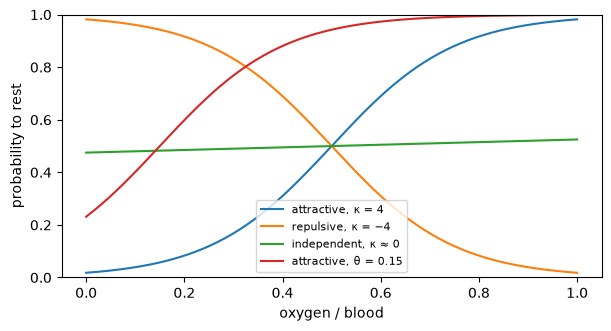

In [6]:
o = np.linspace(0, 1, 200)
fig, axis = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
for kappa, theta, label in [(4, 0.5, "attractive, κ = 4"), (-4, 0.5, "repulsive, κ = −4"),
                            (0.1, 0.5, "independent, κ ≈ 0"), (4, 0.15, "attractive, θ = 0.15")]:
    axis.plot(o, (1 + np.tanh(kappa * (o - theta))) / 2, label=label)
axis.set(xlabel="oxygen / blood", ylabel="probability to rest", ylim=(0, 1))
axis.legend(fontsize=8)
plt.show()

Daughters inherit κ and θ with small normal changes (standard deviations 0.2 and 0.05; θ stays in
[0, 1]), given as the `mutation` of the division rule, so the population evolves.

## 5. Division and death in three oxygen zones

Division and death are step functions of oxygen: one value each in normoxia ($O \ge O_h$, 7 mmHg), hypoxia
($O_a \le O < O_h$) and anoxia ($O < O_a$, 0.7 mmHg). The rule `glioblastoma.oxygen_zones` (a phenotype switch:
it changes traits, not cells) writes the zone's values into the traits `r_b` and `r_d` of every cell, and the
built-in `birth_death` reads them by name. Resting cells divide with `r_b * (1 - n / K)`.

In [7]:
spec = go.build_spec("lin")
for operator in spec.dynamics.operators:
    name = operator["name"] if isinstance(operator, dict) else operator.name
    print(name)
zones = spec.dynamics.operators[2]["parameters"]
print("\ndivision (normoxia, hypoxia, anoxia):", zones["division"])
print("death    (normoxia, hypoxia, anoxia):", zones["death"])

pde
glioblastoma.clogging
glioblastoma.oxygen_zones
birth_death
go_or_rest
birth_death
random_walk

division (normoxia, hypoxia, anoxia): [1.0, 0.5, 0.0]
death    (normoxia, hypoxia, anoxia): [0.1, 0.2, 0.5]


One time step thus runs: oxygen (steady), clogging, the zones, death, the switch, division of resting
cells with mutation, a random walk of migrating cells, and propagation.

## 6. The whole model

### 1D: fixed vessels and clogging

`go.kymographs` runs a 1D model and records cells, oxygen and the mean traits per node. Without clogging the
tumour fills the tissue and oxygen stays patterned by the vessels; with clogging a wave invades ahead of an
anoxic core.

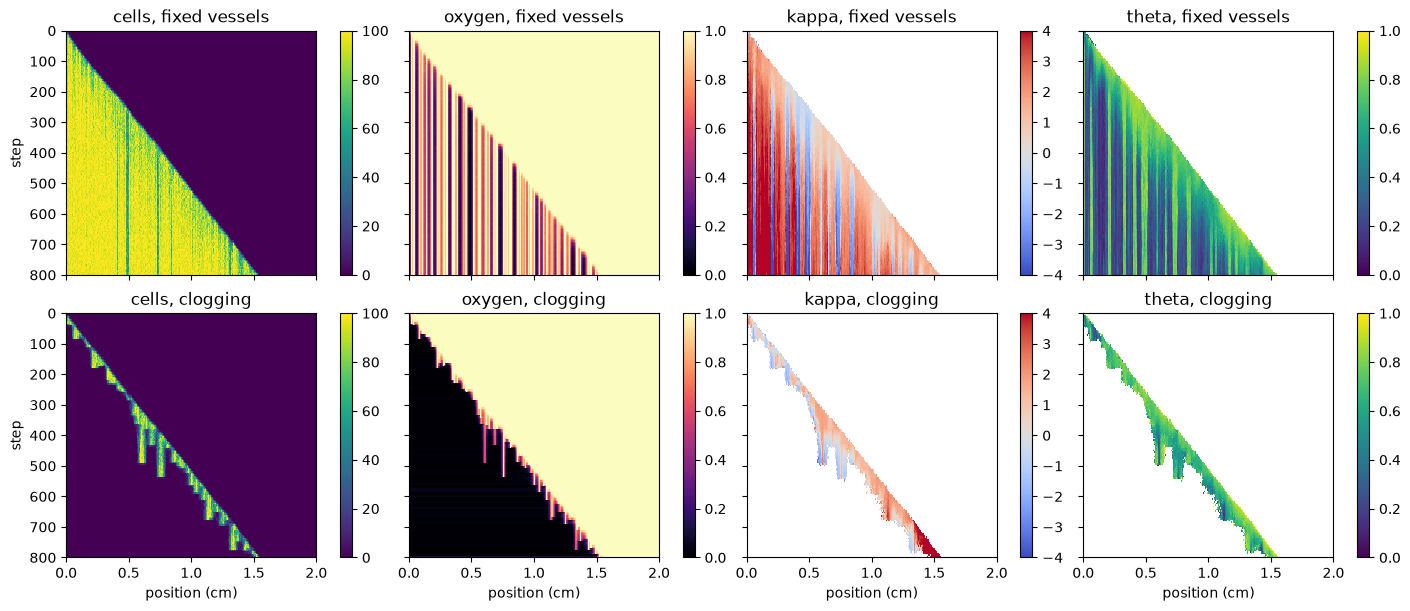

In [8]:
runs = {}
for clogging in (0.0, 0.05):
    runs[clogging] = go.kymographs(go.build_spec("lin", size=400, steps=800, clogging=clogging, seed=1), every=5)

fig, axes = plt.subplots(2, 4, figsize=(14, 6), constrained_layout=True, sharex=True, sharey=True)
for row, (clogging, record) in enumerate(runs.items()):
    extent = (0, 400 * 0.005, record["steps"][-1], 0)
    for axis, key, cmap, vmin, vmax in zip(axes[row], ("cells", "oxygen", "kappa", "theta"),
                                           ("viridis", "magma", "coolwarm", "viridis"),
                                           (0, 0, -4, 0), (100, 1, 4, 1)):
        image = axis.imshow(record[key], aspect="auto", extent=extent, cmap=cmap, vmin=vmin, vmax=vmax,
                            interpolation="nearest")
        axis.set_title(f"{key}, {'clogging' if clogging else 'fixed vessels'}")
        fig.colorbar(image, ax=axis)
for axis in axes[1]:
    axis.set_xlabel("position (cm)")
for axis in axes[:, 0]:
    axis.set_ylabel("step")
plt.show()

### 2D: clogging with stable vessels

On the hexagonal lattice the tumour grows from the centre. With clogging it becomes a ring that invades ahead
of an anoxic core; around the stable vessels (green circles) cells survive inside the core, a perivascular
niche.

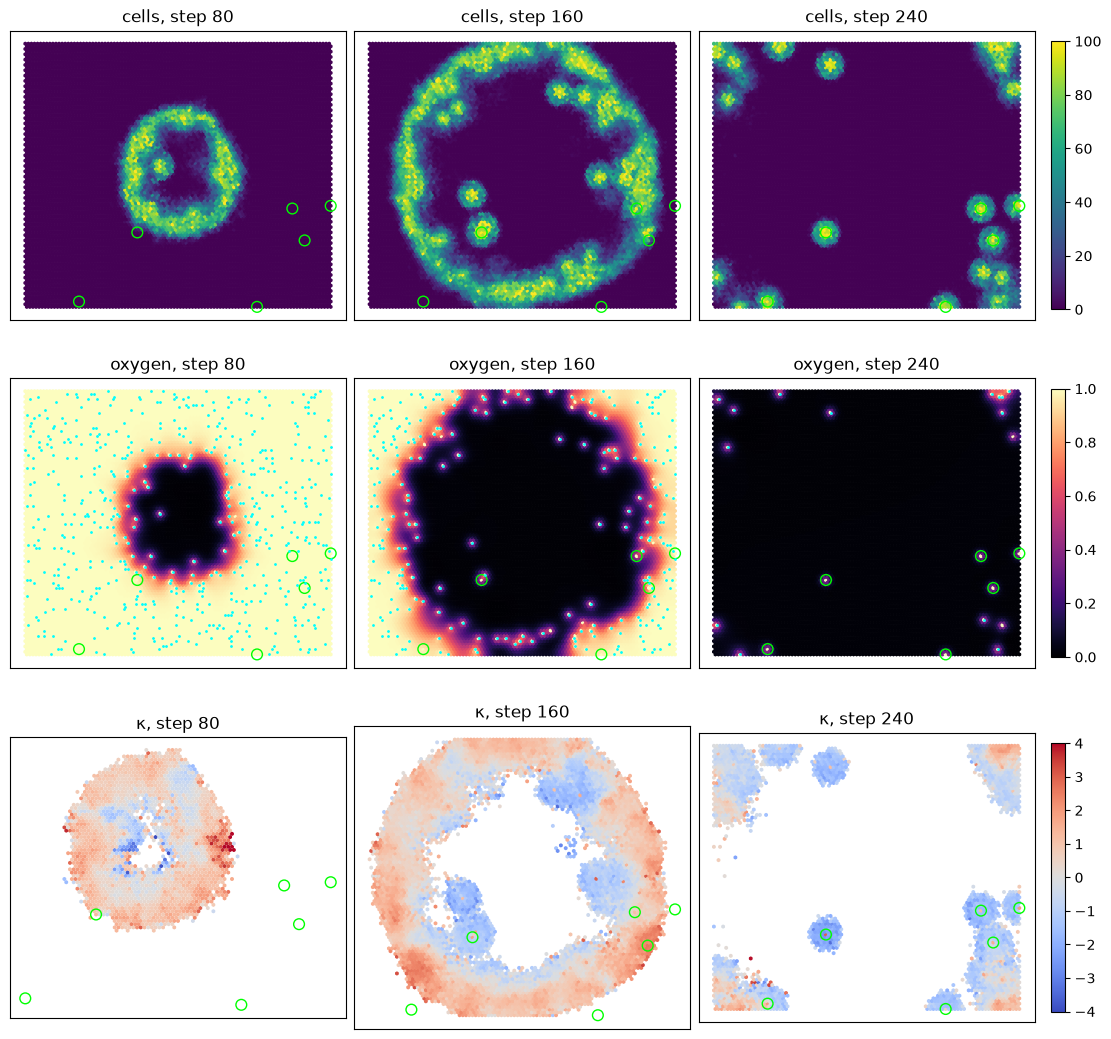

In [9]:
spec2d = go.build_spec("hex", size=100, steps=240, clogging=0.05, stable=6, seed=1)
model = build_model(spec2d)
lgca = model.lgca
x, y = lgca.xcoords, lgca.ycoords
snapshots = (80, 160, 240)
fig, axes = plt.subplots(3, 3, figsize=(11, 10.5), constrained_layout=True)
for column, steps in enumerate(snapshots):
    for _ in range(steps - (snapshots[column - 1] if column else 0)):
        model.step()
    state = LatticeState(lgca)
    oxygen, vessels = state.field("oxygen"), state.field("vessels")
    panels = [(lgca.cell_density[lgca.nonborder], "viridis", 0, 100, "cells"),
              (oxygen, "magma", 0, 1, "oxygen"), (mean_trait(lgca, "kappa"), "coolwarm", -4, 4, "κ")]
    for row, (values, cmap, vmin, vmax, name) in enumerate(panels):
        axis = axes[row, column]
        image = axis.scatter(x.ravel(), y.ravel(), c=values.ravel(), s=4, marker="h", cmap=cmap,
                             vmin=vmin, vmax=vmax)
        axis.scatter(x[vessels == 2], y[vessels == 2], s=60, facecolors="none", edgecolors="lime")
        if name == "oxygen":
            axis.scatter(x[vessels == 1], y[vessels == 1], s=1, c="cyan")
        axis.set(aspect="equal", xticks=[], yticks=[], title=f"{name}, step {steps}")
        if column == 2:
            fig.colorbar(image, ax=axis, shrink=0.8)
plt.show()

### Resection

`resect_at` adds the rule `glioblastoma.resection`: in that step, at every node with at least 10 % of the
capacity, 99.9 % of the cells and all vessels are removed. The cells that remain, mostly at the invasive front
where oxygen is, regrow the tumour.

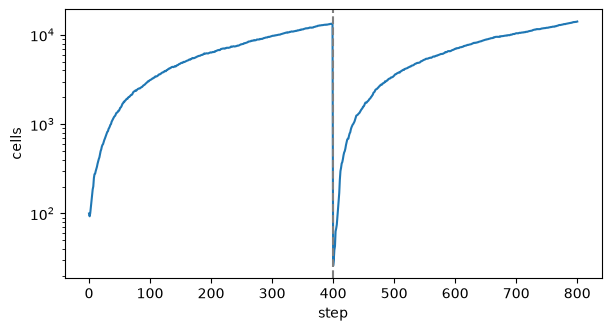

In [10]:
result = run_model(go.build_spec("lin", size=400, steps=800, resect_at=400, seed=2), showprogress=False)
steps = result.data.steps("population")
fig, axis = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
axis.semilogy(steps, np.maximum(result.data["population"], 1))
axis.axvline(400, color="0.5", ls="--")
axis.set(xlabel="step", ylabel="cells")
plt.show()

## References

Syga S, Jain HP, Krellner M, Hatzikirou H, Deutsch A (2024) Evolution of phenotypic plasticity leads to tumor
heterogeneity with implications for therapy. PLoS Comput Biol 20(8): e1012003.

Martínez-González A, Calvo GF, Pérez Romasanta LA, Pérez-García VM (2012) Hypoxic cell waves around necrotic
cores in glioblastoma: a biomathematical model and its therapeutic implications. Bull Math Biol 74:2875–2896.